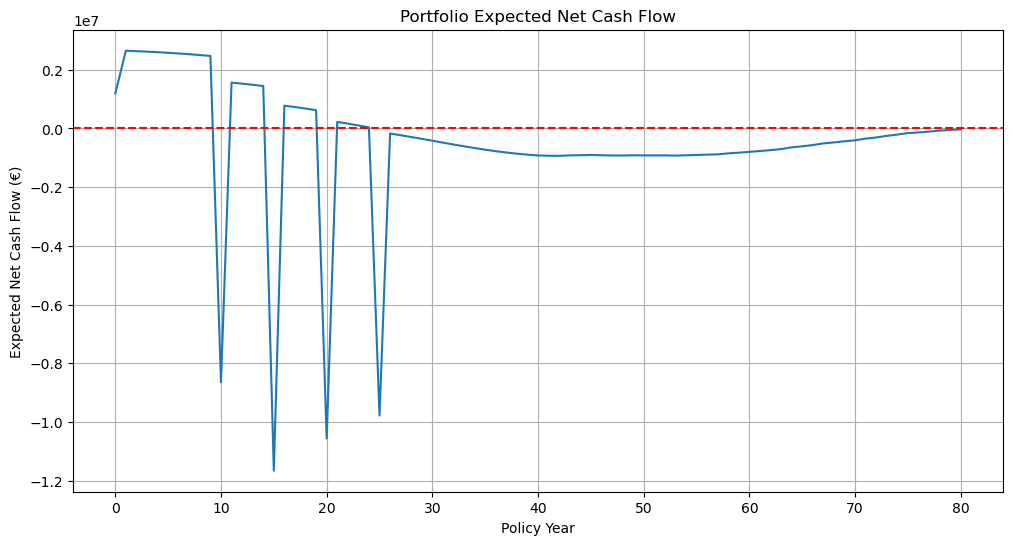

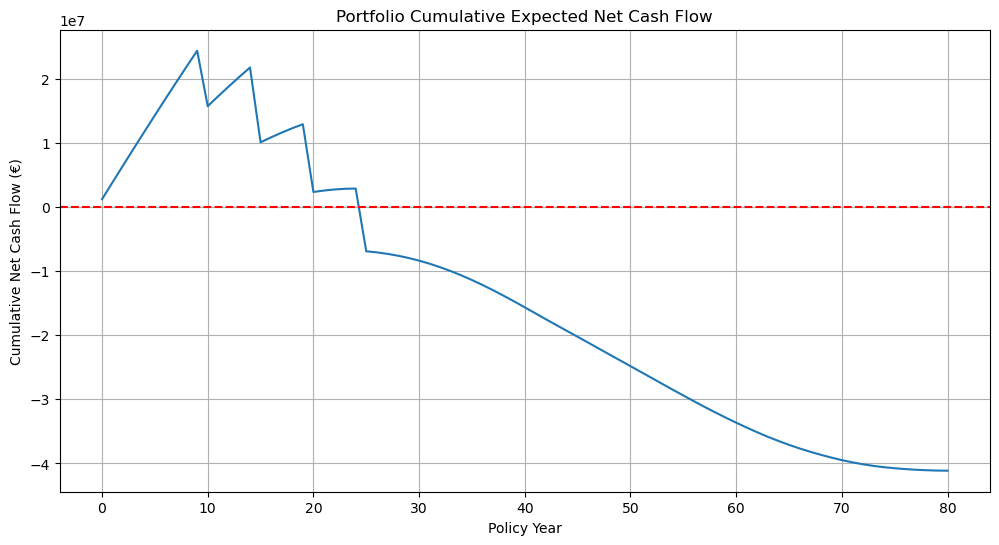

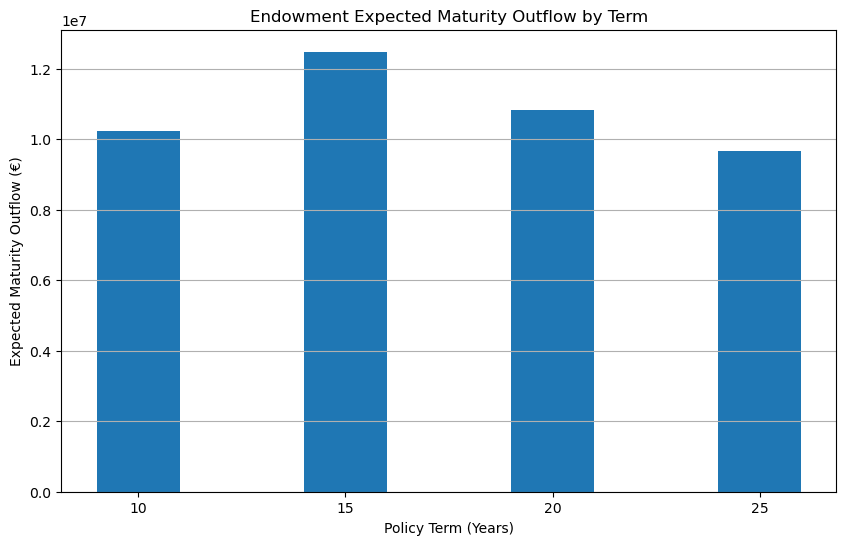

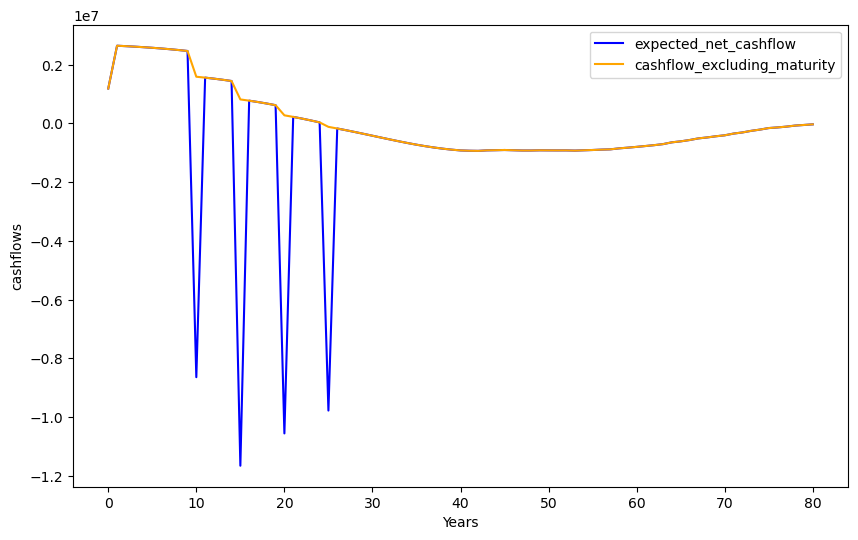

In [139]:
import numpy as np
import pandas as pd
import math

A = 0.00022
B = 0.0000027
c = 1.124

ages = np.arange(20, 101)
px=np.exp(-A-B*(c**ages)*(c-1)/math.log(c))
qx=1-px
mortality_df = pd.DataFrame({
    "Age": ages,
    "px": px,
    "qx": qx
})

kpx=np.append(1,np.cumprod(px[0:(len(px)-1)]))
kpx[0:5]

survival_df=pd.DataFrame({"Age":ages,"k":np.arange(0,81),"kpx":kpx})

import os
project_path = os.getcwd()
os.chdir(project_path)

survival_df.to_csv("survival probabilities.csv",index=False)



#project begins
rng=np.random.default_rng(25)
Portfolio_Attributes=pd.DataFrame({"policy_id":np.arange(1,501),
                                   "age":rng.integers(20,61,size=500),
                                   "term":rng.choice([10,15,20,25],size=500)})
Portfolio_Attributes["sum_insured"]=rng.choice(np.arange(50000,510000,10000),size=500)
Portfolio_Attributes["product_type"]=rng.choice(["Term","Whole Life","Endowment"],size=500)
Portfolio_Attributes["product_type"].value_counts()
Portfolio_Attributes.isna().sum()
Portfolio_Attributes["policy_id"].duplicated().sum()
Portfolio_Attributes["age"].min()
Portfolio_Attributes["age"].max()
Portfolio_Attributes["sum_insured"].max()
Portfolio_Attributes["sum_insured"].min()
Portfolio_Attributes.to_csv("insurance_portfolio.csv",index=False)

#Actuarial Functions
def survival_probability(age,term):
    tpx=np.prod(px[(age-20):(age+term-20)])
    return tpx


def term_insurance_epv(age, term, sum_insured,interest):
    v=1/(1+interest)
    kpx_besides_kp0=np.cumprod(px[(age-20):(term-21+age)])
    kpx=np.append(1,kpx_besides_kp0)
    death_probs=1-px[(age-20):(term+age-20)]
    discount_factors=v**(np.arange(1,term+1))
    epv=sum(sum_insured*discount_factors*death_probs*kpx)
    return epv

Portfolio_Attributes["term_epv"]=Portfolio_Attributes.apply(lambda row: term_insurance_epv(row["age"],row["term"],row["sum_insured"],
                                                                                       0.04) if row["product_type"]=="Term" else 0,axis=1)

def endowment_insurance_epv(age, term, death_benefit, maturity_benefit, interest):
    term_part = term_insurance_epv(age, term, death_benefit, interest)

    v = 1 / (1 + interest)
    npx = np.prod(px[(age-20):(age+term-20)])
    discount_factor = v**term

    pure_endowment = maturity_benefit * npx * discount_factor

    epv = term_part + pure_endowment
    return epv

rng_maturity = np.random.default_rng(26)
Portfolio_Attributes["maturity_benefit"] = np.where(
    Portfolio_Attributes["product_type"] == "Endowment",
    rng_maturity.choice(np.arange(50000,510000,10000),size=500),
    0
)

Portfolio_Attributes["endowment_epv"]=Portfolio_Attributes.apply(lambda row: endowment_insurance_epv(row["age"],
                                                                                                     row["term"],
                                                                                                     row["sum_insured"],
                                                                                                     row["maturity_benefit"],
                                                                                                     0.04) if row["product_type"]=="Endowment" else 0 ,axis=1)

def whole_life_epv(age,sum_insured,interest):
    v=1/(1+interest)
    kpx=np.append(1,np.cumprod(px[(age-20):(len(px)-1)]))
    mortality=1-px[(age-20):len(px)]
    discount_factors=v**(np.arange(1,(len(mortality)+1)))
    epv=sum(kpx*discount_factors*mortality*sum_insured)
    return epv
Portfolio_Attributes["whole_life_epv"]=Portfolio_Attributes.apply( lambda row:whole_life_epv(row["age"],
                                                                                             row["sum_insured"],
                                                                                             0.04) if row["product_type"]=="Whole Life" else 0,axis=1)
Portfolio_Attributes["net single_premium"] = (
    Portfolio_Attributes["term_epv"]
    + Portfolio_Attributes["whole_life_epv"]
    + Portfolio_Attributes["endowment_epv"]
)
def life_annuity_due_epv(age, term, interest):
    v = 1 / (1 + interest)
    k = np.arange(0, term)
    kpx = np.append(
        1,
        np.cumprod(px[(age-20):(age+term-21)])
    )
    discount_factors = v**k
    epv = np.sum(kpx * discount_factors)
    return epv
def whole_life_annuity_due_epv(age, interest):
    v = 1 / (1 + interest)
    kpx = np.append(
        1,
        np.cumprod(px[(age-20):(len(px)-1)])
    )
    discount_factors = v**np.arange(len(kpx))
    epv = np.sum(kpx * discount_factors)
    return epv
def net_annual_premium(age, term, sum_insured, maturity_benefit, product_type, interest):

    if product_type == "Term":
        benefit_epv = term_insurance_epv(
            age, term, sum_insured, interest
        )
        annuity_epv = life_annuity_due_epv(
            age, term, interest
        )

    elif product_type == "Endowment":
        benefit_epv = endowment_insurance_epv(
            age, term, sum_insured, maturity_benefit, interest
        )
        annuity_epv = life_annuity_due_epv(
            age, term, interest
        )

    elif product_type == "Whole Life":
        benefit_epv = whole_life_epv(
            age, sum_insured, interest
        )
        annuity_epv = whole_life_annuity_due_epv(
            age, interest
        )

    else:
        raise ValueError("Unknown product type")

    return benefit_epv / annuity_epv
Portfolio_Attributes["net_annual_premium"] = Portfolio_Attributes.apply(lambda row:net_annual_premium(row["age"],
                                                                                                      row["term"], 
                                                                                                      row["sum_insured"],
                                                                                                      row["maturity_benefit"],
                                                                                                      row["product_type"],
                                                                                                     0.04),axis=1)
def gross_annual_premium(age, term, sum_insured, maturity_benefit, product_type, interest):

    if product_type == "Whole Life":
        benefit_epv = whole_life_epv(
            age, sum_insured, interest
        )
        annuity_epv = whole_life_annuity_due_epv(
            age, interest
        )

    elif product_type == "Term":
        benefit_epv = term_insurance_epv(
            age, term, sum_insured, interest
        )
        annuity_epv = life_annuity_due_epv(
            age, term, interest
        )

    elif product_type == "Endowment":
        benefit_epv = endowment_insurance_epv(
            age, term, sum_insured, maturity_benefit, interest
        )
        annuity_epv = life_annuity_due_epv(
            age, term, interest
        )

    else:
        raise ValueError("Unknown product type")

    initial_expense = 150
    renewal_expense = 20
    commission_rate = 0.5
    gross_premium=(benefit_epv+initial_expense+renewal_expense*annuity_epv)/(annuity_epv-commission_rate)

    return gross_premium

Portfolio_Attributes["gross_annual_premium"] = Portfolio_Attributes.apply(lambda row:gross_annual_premium(row["age"],
                                                                                                          row["term"],
                                                                                                          row["sum_insured"],
                                                                                                          row["maturity_benefit"],
                                                                                                          row["product_type"],
                                                                                                          0.04),axis=1)
Portfolio_Attributes["expense_loading"]=Portfolio_Attributes["gross_annual_premium"]-Portfolio_Attributes["net_annual_premium"]
Portfolio_Attributes["loading_ratio"]=Portfolio_Attributes["expense_loading"]/Portfolio_Attributes["net_annual_premium"]

product_summary = Portfolio_Attributes.groupby("product_type").agg(
    policy_count=("policy_id", "count"),
    total_sum_insured=("sum_insured", "sum"),
    average_sum_insured=("sum_insured", "mean")
)

age_summary = Portfolio_Attributes.groupby("product_type")["age"].agg(["min","max","mean","median"])

premium_summary = Portfolio_Attributes.groupby("product_type").agg(
    average_net_premium=("net_annual_premium", "mean"),
    average_gross_premium=("gross_annual_premium", "mean"),
    average_loading_ratio=("loading_ratio", "mean")
)
def expected_premium_cash_inflow(age, term, sum_insured, maturity_benefit, gross_premium, product_type, year):
    if age+year>100:
        return 0
    survival_prob = survival_probability(age, year)
    renewal_expense = 20 * survival_prob
    initial_expense = 150 if year == 0 else 0
    commission = 0.5 * gross_premium if year == 0 else 0
    if product_type == "Term":
        if year>=term:
            return 0
        death_prob = qx[age + year - 20]
        premium_inflow = gross_premium * survival_prob
        cash_outflow=sum_insured*survival_prob*death_prob+renewal_expense+initial_expense+commission
        cash_inflow=premium_inflow-cash_outflow
        return cash_inflow

    if product_type=="Endowment":
        survival_prob = survival_probability(age, year)
        if year>term:
            return 0
        if year==term:
            maturity_outflow = maturity_benefit * survival_prob
            return -maturity_outflow
        death_prob = qx[age + year - 20]
        premium_inflow = gross_premium * survival_prob
        cash_outflow=sum_insured*survival_prob*death_prob+renewal_expense+initial_expense+commission
        cash_inflow=premium_inflow-cash_outflow
        return cash_inflow
    if product_type=="Whole Life":
        death_prob = qx[age + year - 20]
        premium_inflow = gross_premium * survival_prob
        cash_outflow=sum_insured*survival_prob*death_prob+renewal_expense+initial_expense+commission
        cash_inflow=premium_inflow-cash_outflow
        return cash_inflow
Portfolio_Attributes["cashflow_year_0"] = Portfolio_Attributes.apply(
    lambda row: expected_premium_cash_inflow(
        row["age"],
        row["term"],
        row["sum_insured"],
        row["maturity_benefit"],
        row["gross_annual_premium"],
        row["product_type"],
        0),axis=1)

years = np.arange(0, 81)
portfolio_cashflows = []      
for year in years:
    yearly_cashflow = Portfolio_Attributes.apply(
        lambda row: expected_premium_cash_inflow(
            row["age"],
            row["term"],
            row["sum_insured"],
            row["maturity_benefit"],
            row["gross_annual_premium"],
            row["product_type"],
            year),axis=1).sum()
    portfolio_cashflows.append(yearly_cashflow)   
cashflow_df = pd.DataFrame({"year": years,"expected_net_cashflow": portfolio_cashflows})


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))


plt.plot(
    cashflow_df["year"],
    cashflow_df["expected_net_cashflow"]
)

plt.axhline(y=0,color="red",linestyle="--")
plt.xlabel("Policy Year")
plt.ylabel("Expected Net Cash Flow (€)")
plt.title("Portfolio Expected Net Cash Flow")
plt.grid(True)
plt.show()
selected_years = [10, 15, 20, 25]

cashflow_df[cashflow_df["year"].isin(selected_years)]
cashflow_df["cumulative_cashflow"] = (cashflow_df["expected_net_cashflow"].cumsum())
cashflow_df[ ["year", "expected_net_cashflow", "cumulative_cashflow"]].head(30)

plt.figure(figsize=(12, 6))

plt.plot(cashflow_df["year"],cashflow_df["cumulative_cashflow"])
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Policy Year")
plt.ylabel("Cumulative Net Cash Flow (€)")
plt.title("Portfolio Cumulative Expected Net Cash Flow")
plt.grid(True)
plt.show()
endowment_summary = (Portfolio_Attributes[Portfolio_Attributes["product_type"] == "Endowment"].groupby("term").agg(policy_count=("policy_id", "count"),
                                                                                                                   total_maturity_benefit=
                                                                                                                   ("maturity_benefit", "sum")))

endowment_df = Portfolio_Attributes[
    Portfolio_Attributes["product_type"] == "Endowment"
].copy()

endowment_df["expected_maturity_outflow"] = endowment_df.apply(
    lambda row: row["maturity_benefit"] *
    survival_probability(row["age"], row["term"]),
    axis=1
)

maturity_summary = endowment_df.groupby("term").agg(
    policy_count=("policy_id", "count"),
    expected_maturity_outflow=("expected_maturity_outflow", "sum")
)

maturity_summary

plt.figure(figsize=(10, 6))
plt.bar(maturity_summary.index,
        maturity_summary["expected_maturity_outflow"],
        width=2)

plt.xlabel("Policy Term (Years)")
plt.ylabel("Expected Maturity Outflow (€)")
plt.title("Endowment Expected Maturity Outflow by Term")
plt.xticks(maturity_summary.index)
plt.grid(axis="y")

plt.show()
maturity_impact=cashflow_df.merge(maturity_summary[["expected_maturity_outflow"]],left_on="year",right_index=True,how="left")
maturity_impact["expected_maturity_outflow"]=maturity_impact["expected_maturity_outflow"].fillna(0)


maturity_impact["cashflow_excluding_maturity"]=maturity_impact["expected_net_cashflow"]+maturity_impact["expected_maturity_outflow"]
plt.figure(figsize=(10, 6))
plt.plot(maturity_impact["year"],maturity_impact["expected_net_cashflow"],label="expected_net_cashflow",color="blue")
plt.plot(maturity_impact["year"],maturity_impact["cashflow_excluding_maturity"],label="cashflow_excluding_maturity",color="orange")
plt.xlabel("Years")
plt.ylabel("cashflows")
plt.legend()
plt.show()


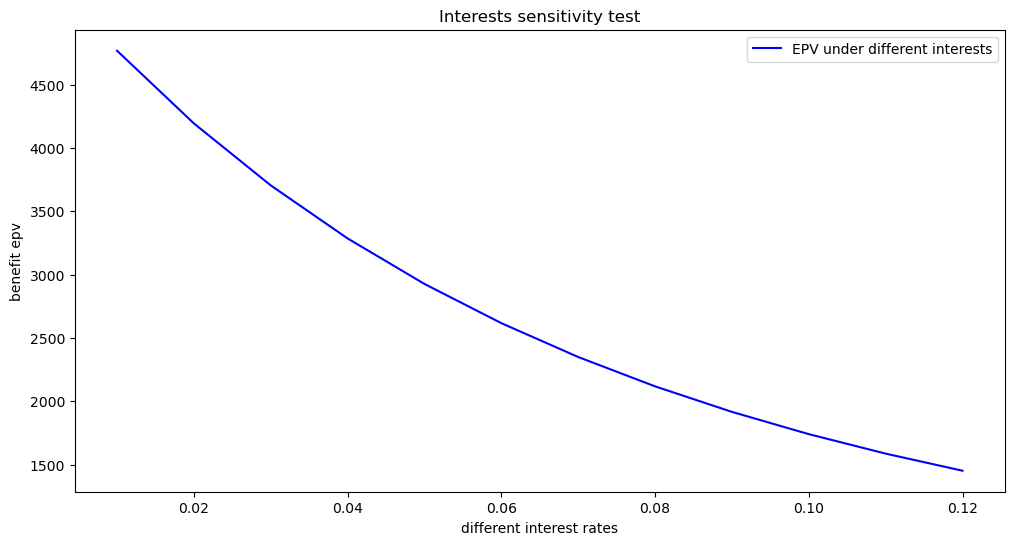

In [140]:
interest_rates=np.arange(0.01,0.13,0.01)
epv_results = []

for interest in interest_rates:
    epv=term_insurance_epv(40, 20, 200000, interest)
    epv_results.append(epv)

interest_sensitivity=pd.DataFrame({"interest_rate":interest_rates,
                                   "benefit_epv":epv_results})
plt.figure(figsize=(12,6))
plt.plot(interest_sensitivity["interest_rate"],interest_sensitivity["benefit_epv"],label="EPV under different interests",color="blue")
plt.legend()
plt.xlabel("different interest rates")
plt.ylabel("benefit epv")
plt.title("Interests sensitivity test")
plt.show()

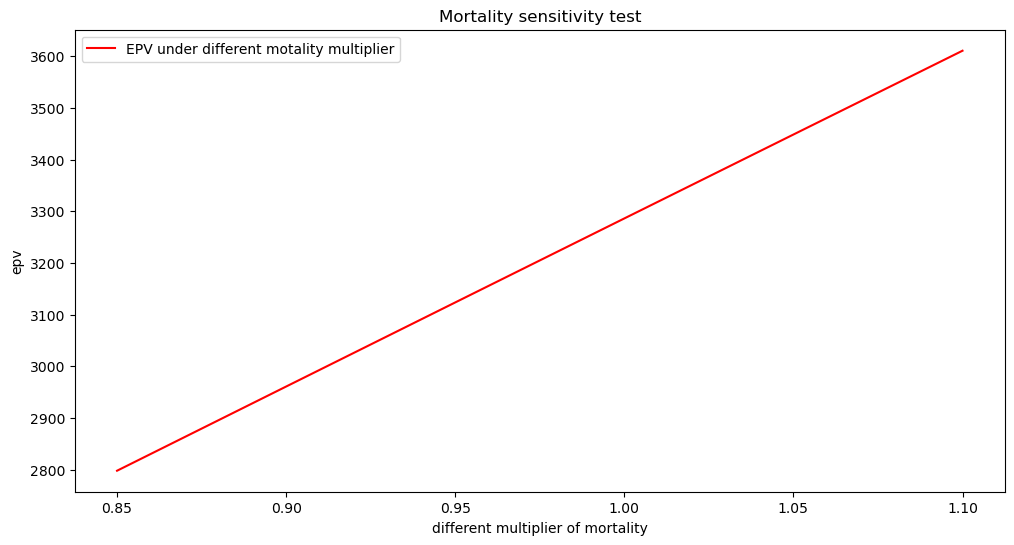

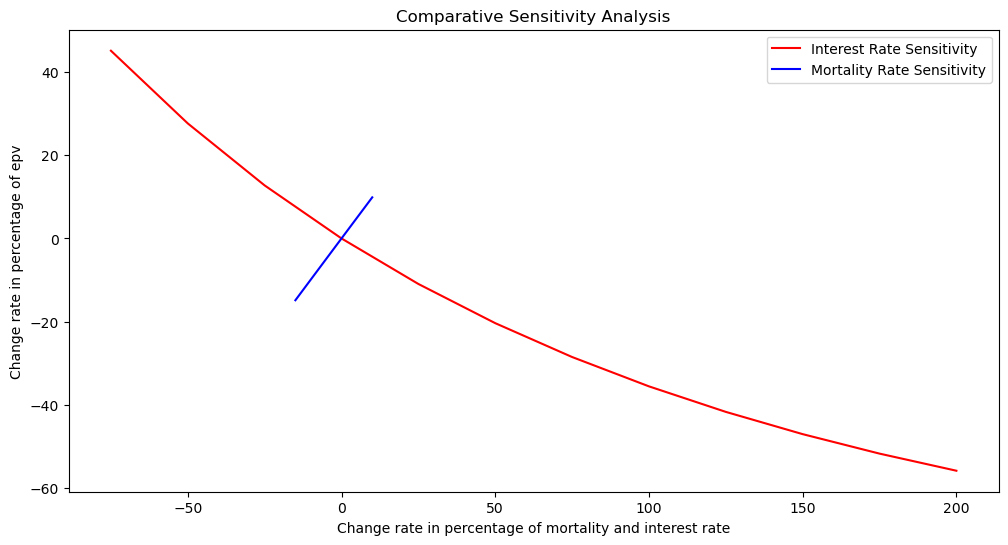

In [150]:
mortality_multipliers=np.arange(0.85,1.15,0.05)
adjusted_qx=[]
for i in range(0,6):
    adjusted_qx.append(mortality_multipliers[i]*qx)
    

adjusted_px_result=[]
for i in range(len(adjusted_qx)):
    adjusted_px=[]
    qx_list=adjusted_qx[i]
    for k in range(len(qx_list)):
        adjusted_px.append(1-qx_list[k])
    adjusted_px_result.append(adjusted_px)
    
def term_insurance_epv_adjusted(age, term, sum_insured, interest, adjusted_px_result, adjusted_qx):
    v = 1 / (1 + interest)
    kpx_besides_kp0 = np.cumprod(adjusted_px_result[(age-20):(term-21+age)])
    kpx = np.append(1, kpx_besides_kp0)
    death_probs = adjusted_qx[(age-20):(term+age-20)]
    discount_factors = v**(np.arange(1, term+1))
    epv = sum(sum_insured * discount_factors * death_probs * kpx)
    return epv

mortality_epv_results = []
for i in range(len(adjusted_qx)):
    epv=term_insurance_epv_adjusted(40, 20, 200000, 0.04,adjusted_px_result[i],adjusted_qx[i])
    mortality_epv_results.append(epv)
mortality_sensitivity=pd.DataFrame({"mortality_multiplier":mortality_multipliers,
                                    "epv":mortality_epv_results})
mortality_sensitivity
plt.figure(figsize=(12,6))
plt.plot(mortality_sensitivity["mortality_multiplier"],mortality_sensitivity["epv"],label="EPV under different motality multiplier",color="red")
plt.xlabel("different multiplier of mortality")
plt.ylabel("epv")
plt.legend()
plt.title("Mortality sensitivity test")


base_epv = term_insurance_epv(40, 20, 200000, 0.04)
interest_sensitivity["epv_change_pct"] = ((interest_sensitivity["benefit_epv"] - base_epv) / base_epv * 100)
mortality_sensitivity["epv_change_pct"] = ((mortality_sensitivity["epv"] - base_epv) / base_epv * 100)

interest_sensitivity["factor_change_pct"] = ((interest_sensitivity["interest_rate"] - 0.04) / 0.04 * 100)
mortality_sensitivity["factor_change_pct"] = ((mortality_sensitivity["mortality_multiplier"] - 1.0) * 100)

plt.figure(figsize=(12,6))
plt.plot(interest_sensitivity["factor_change_pct"],interest_sensitivity["epv_change_pct"],
         label="Interest Rate Sensitivity",color="red")
plt.plot(mortality_sensitivity["factor_change_pct"],mortality_sensitivity["epv_change_pct"],
         label="Mortality Rate Sensitivity",color="blue")
plt.legend()
plt.xlabel("Change rate in percentage of mortality and interest rate")
plt.ylabel("Change rate in percentage of epv")
plt.title("Comparative Sensitivity Analysis")
plt.show()




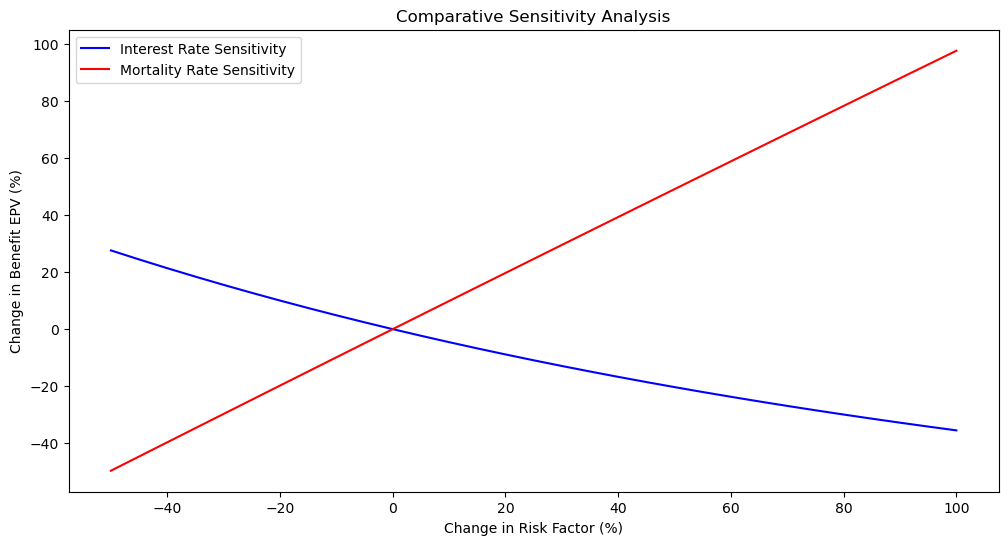

In [157]:
def comparative_sensitivity(change_rate):
    base_epv=term_insurance_epv(40,20,200000,0.04)
    adjusted_interest=0.04*(1+change_rate)
    adjusted_qx=qx*(1+change_rate)
    adjusted_px=1-adjusted_qx

    interest_epv=term_insurance_epv(40,20,200000,adjusted_interest)
    mortality_epv=term_insurance_epv_adjusted(40,20,200000,0.04,adjusted_px,adjusted_qx)

    interest_change_pct=(interest_epv-base_epv)/base_epv*100
    mortality_change_pct=(mortality_epv-base_epv)/base_epv*100

    return interest_change_pct,mortality_change_pct


change_rates=np.arange(-0.50,1.05,0.05)
interest_change_results=[]
mortality_change_results=[]

for change_rate in change_rates:
    interest_change_pct,mortality_change_pct=comparative_sensitivity(change_rate)
    interest_change_results.append(interest_change_pct)
    mortality_change_results.append(mortality_change_pct)

comparative_results=pd.DataFrame({"change_rate":change_rates,
                                  "interest_epv_change_pct":interest_change_results,
                                  "mortality_epv_change_pct":mortality_change_results})
comparative_results

plt.figure(figsize=(12,6))
plt.plot(comparative_results["change_rate"]*100,comparative_results["interest_epv_change_pct"],label="Interest Rate Sensitivity",color="blue")
plt.plot(comparative_results["change_rate"]*100,comparative_results["mortality_epv_change_pct"],label="Mortality Rate Sensitivity",color="red")
plt.xlabel("Change in Risk Factor (%)")
plt.ylabel("Change in Benefit EPV (%)")
plt.title("Comparative Sensitivity Analysis")
plt.legend()
plt.show()

product_type
Endowment     45100000
Term          45670000
Whole Life    49760000
Name: sum_insured, dtype: int64
product_type
Endowment     32.092792
Term          32.498399
Whole Life    35.408810
Name: sum_insured, dtype: float64


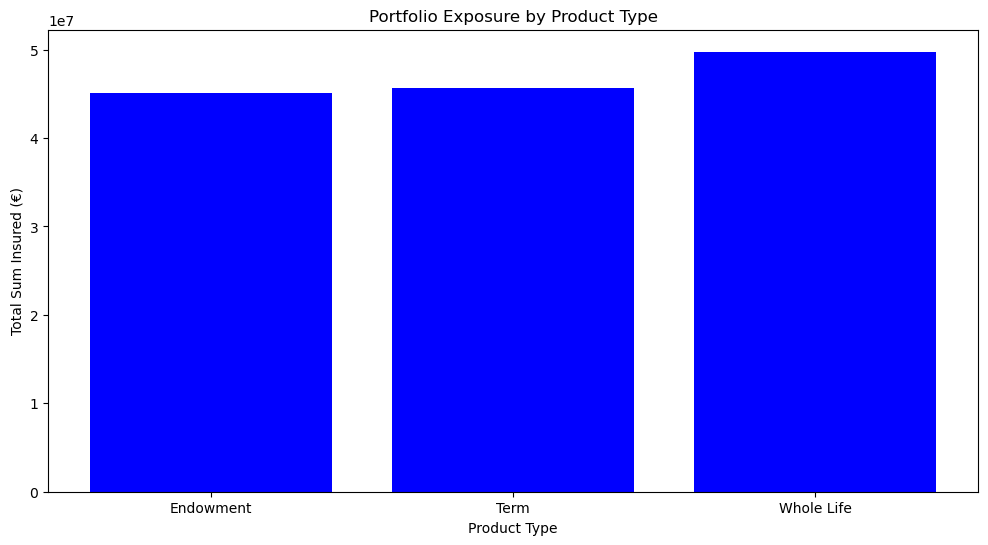

product_type
Endowment     2.326933e+07
Term          1.178370e+06
Whole Life    9.698098e+06
Name: benefit_epv, dtype: float64
product_type
Endowment     68.146978
Term           3.450997
Whole Life    28.402026
Name: benefit_epv, dtype: float64


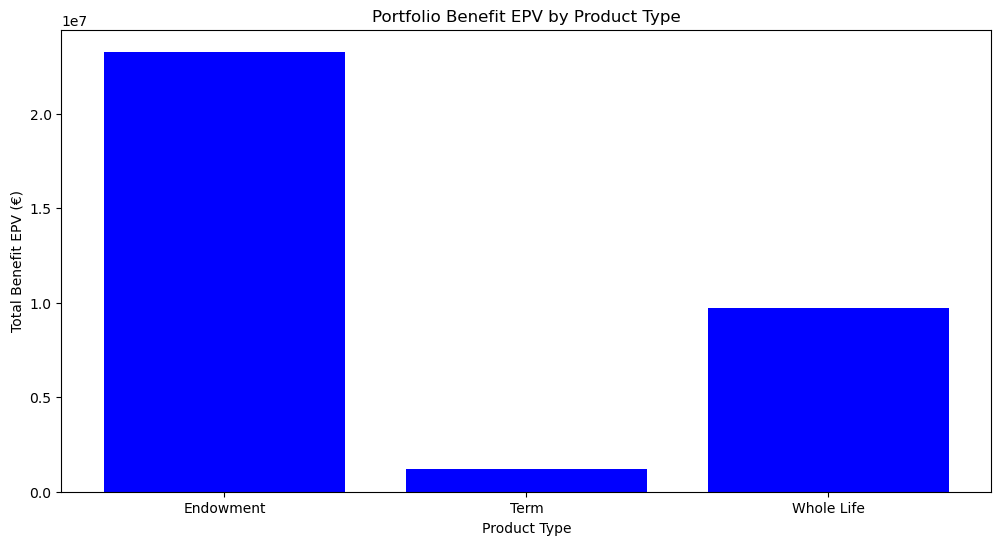

              total_sum_insured  sum_insured_pct  total_benefit_epv  \
product_type                                                          
Endowment              45100000        32.092792       2.326933e+07   
Term                   45670000        32.498399       1.178370e+06   
Whole Life             49760000        35.408810       9.698098e+06   

              benefit_epv_pct  concentration_ratio  
product_type                                        
Endowment           68.146978             2.123436  
Term                 3.450997             0.106190  
Whole Life          28.402026             0.802118  


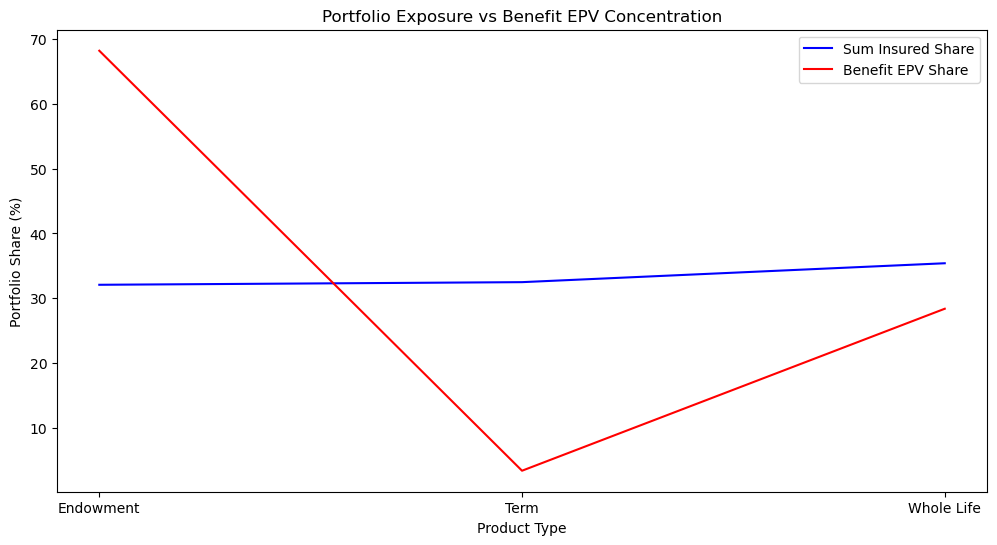

In [168]:
product_exposure=Portfolio_Attributes.groupby("product_type")["sum_insured"].sum()
product_exposure_pct=product_exposure/product_exposure.sum()*100

print(product_exposure)
print(product_exposure_pct)

plt.figure(figsize=(12,6))
plt.bar(product_exposure.index,product_exposure.values,color="blue")
plt.xlabel("Product Type")
plt.ylabel("Total Sum Insured (€)")
plt.title("Portfolio Exposure by Product Type")
plt.show()


# Stage 9.2 — Portfolio Benefit EPV Analysis

Portfolio_Attributes["benefit_epv"]=Portfolio_Attributes["term_epv"]+Portfolio_Attributes["whole_life_epv"]+Portfolio_Attributes["endowment_epv"]

product_epv=Portfolio_Attributes.groupby("product_type")["benefit_epv"].sum()
product_epv_pct=product_epv/product_epv.sum()*100

print(product_epv)
print(product_epv_pct)

plt.figure(figsize=(12,6))
plt.bar(product_epv.index,product_epv.values,color="blue")
plt.xlabel("Product Type")
plt.ylabel("Total Benefit EPV (€)")
plt.title("Portfolio Benefit EPV by Product Type")
plt.show()



liability_concentration=pd.DataFrame({"total_sum_insured":product_exposure,
                                      "sum_insured_pct":product_exposure_pct,
                                      "total_benefit_epv":product_epv,
                                      "benefit_epv_pct":product_epv_pct})

liability_concentration["concentration_ratio"]=liability_concentration["benefit_epv_pct"]/liability_concentration["sum_insured_pct"]

print(liability_concentration)

plt.figure(figsize=(12,6))
plt.plot(liability_concentration.index,liability_concentration["sum_insured_pct"],label="Sum Insured Share",color="blue")
plt.plot(liability_concentration.index,liability_concentration["benefit_epv_pct"],label="Benefit EPV Share",color="red")
plt.xlabel("Product Type")
plt.ylabel("Portfolio Share (%)")
plt.title("Portfolio Exposure vs Benefit EPV Concentration")
plt.legend()
plt.show()




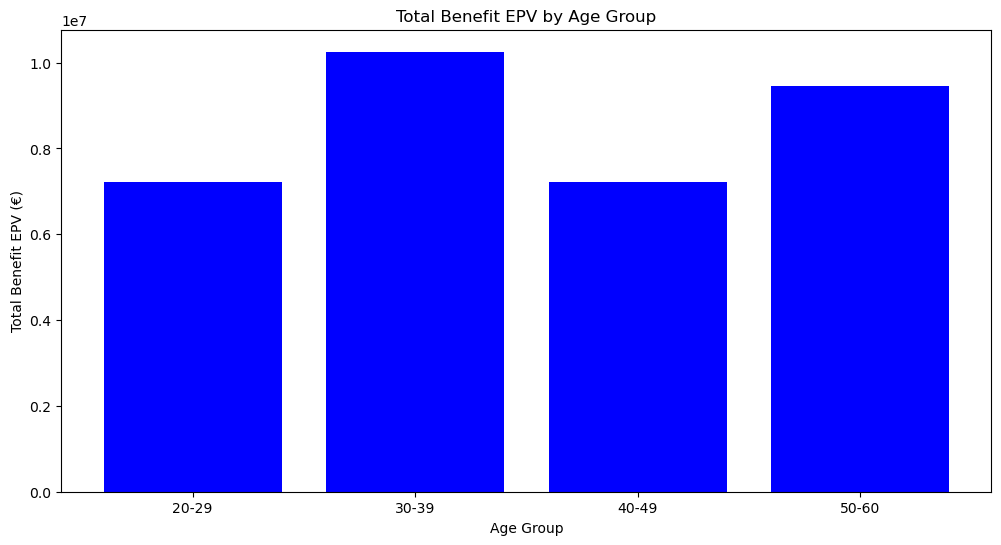

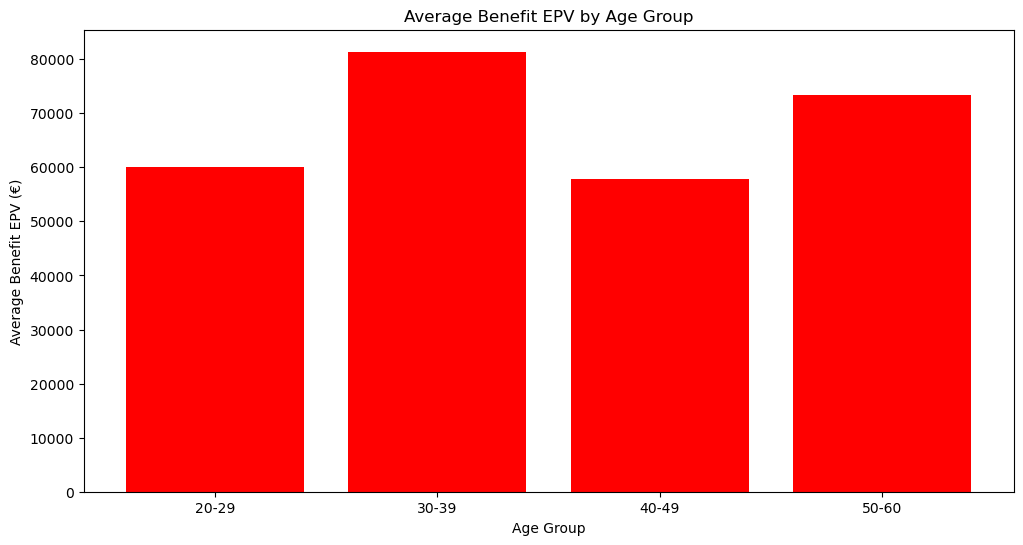

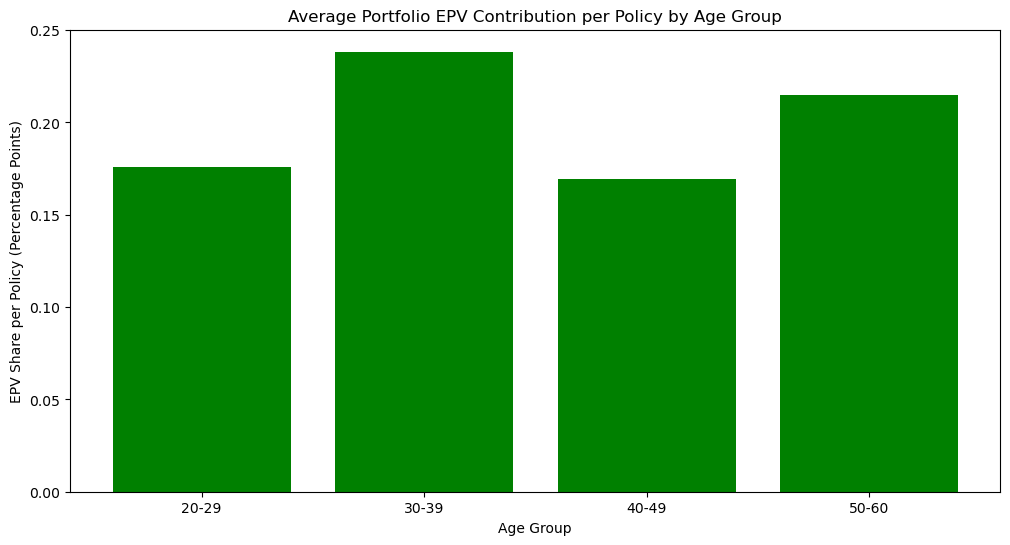

In [169]:
age_groups=[]
for age in Portfolio_Attributes["age"]:
    if age<30:
        age_groups.append("20-29")
    elif age<40:
        age_groups.append("30-39")
    elif age<50:
        age_groups.append("40-49")
    else:
        age_groups.append("50-60")

Portfolio_Attributes["age_group"]=age_groups

age_risk_summary=Portfolio_Attributes.groupby("age_group").agg(
    policy_count=("policy_id","count"),
    total_sum_insured=("sum_insured","sum"),
    total_benefit_epv=("benefit_epv","sum"),
    average_benefit_epv=("benefit_epv","mean"))

age_risk_summary["epv_share_pct"]=age_risk_summary["total_benefit_epv"]/age_risk_summary["total_benefit_epv"].sum()*100
age_risk_summary["epv_share_per_policy"]=age_risk_summary["epv_share_pct"]/age_risk_summary["policy_count"]

age_risk_summary


plt.figure(figsize=(12,6))
plt.bar(age_risk_summary.index,age_risk_summary["total_benefit_epv"],color="blue")
plt.xlabel("Age Group")
plt.ylabel("Total Benefit EPV (€)")
plt.title("Total Benefit EPV by Age Group")
plt.show()

plt.figure(figsize=(12,6))
plt.bar(age_risk_summary.index,age_risk_summary["average_benefit_epv"],color="red")
plt.xlabel("Age Group")
plt.ylabel("Average Benefit EPV (€)")
plt.title("Average Benefit EPV by Age Group")
plt.show()

plt.figure(figsize=(12,6))
plt.bar(age_risk_summary.index,age_risk_summary["epv_share_per_policy"],color="green")
plt.xlabel("Age Group")
plt.ylabel("EPV Share per Policy (Percentage Points)")
plt.title("Average Portfolio EPV Contribution per Policy by Age Group")
plt.show()

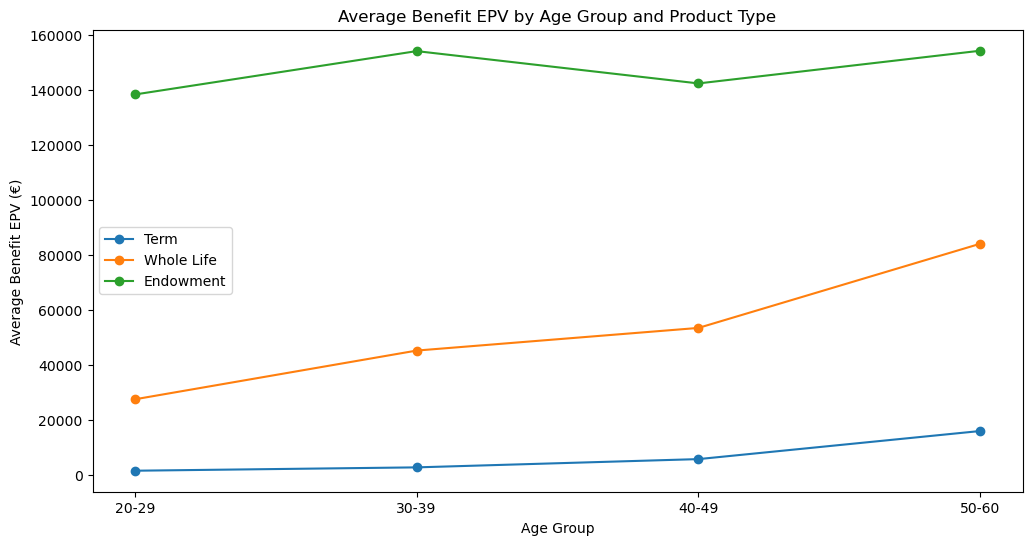

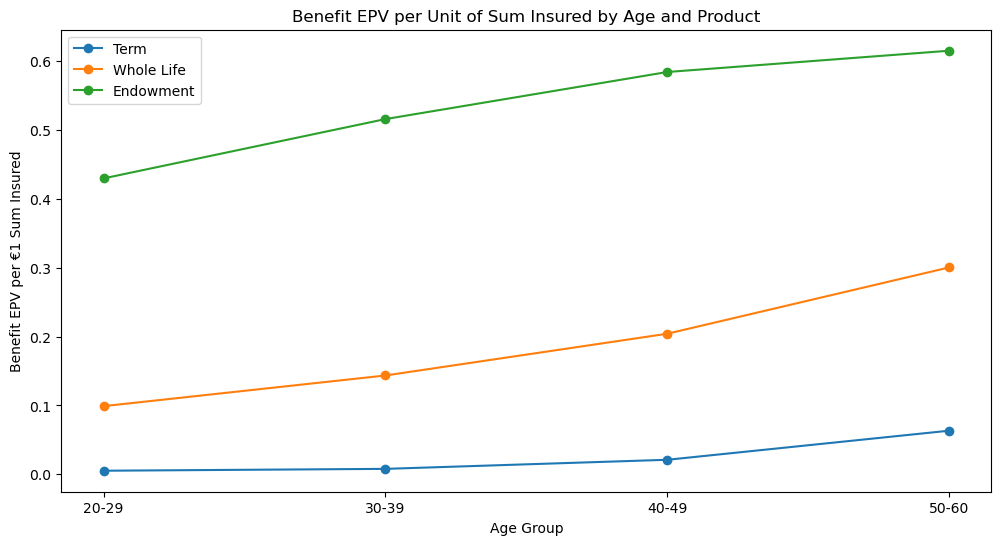

In [173]:
# Stage 9.6 — Age and Product Risk Analysis

age_product_summary=Portfolio_Attributes.groupby(["product_type","age_group"]).agg(
    policy_count=("policy_id","count"),
    total_sum_insured=("sum_insured","sum"),
    total_benefit_epv=("benefit_epv","sum"),
    average_benefit_epv=("benefit_epv","mean")
)

age_product_summary["epv_share_pct"]=age_product_summary["total_benefit_epv"]/age_product_summary["total_benefit_epv"].sum()*100
age_product_summary["epv_share_per_policy"]=age_product_summary["epv_share_pct"]/age_product_summary["policy_count"]

age_product_summary

plt.figure(figsize=(12,6))

for product in ["Term","Whole Life","Endowment"]:
    product_data=age_product_summary.loc[product]
    plt.plot(product_data.index,product_data["average_benefit_epv"],label=product,marker="o")

plt.xlabel("Age Group")
plt.ylabel("Average Benefit EPV (€)")
plt.title("Average Benefit EPV by Age Group and Product Type")
plt.legend()
plt.show()

age_product_summary["epv_per_sum_insured"]=age_product_summary["total_benefit_epv"]/age_product_summary["total_sum_insured"]
age_product_summary

plt.figure(figsize=(12,6))

for product in ["Term","Whole Life","Endowment"]:
    product_data=age_product_summary.loc[product]
    plt.plot(product_data.index,product_data["epv_per_sum_insured"],label=product,marker="o")

plt.xlabel("Age Group")
plt.ylabel("Benefit EPV per €1 Sum Insured")
plt.title("Benefit EPV per Unit of Sum Insured by Age and Product")
plt.legend()
plt.show()

Top X: 25
Concentration (%): 20.475246126487278
     policy_id  age product_type  sum_insured    benefit_epv  epv_share_pct
304        305   51    Endowment       240000  334517.235609       0.979673
25          26   34    Endowment       360000  330805.726816       0.968804
357        358   35    Endowment       130000  329830.090289       0.965946
329        330   47    Endowment       290000  329526.685713       0.965058
428        429   29    Endowment       410000  317552.644525       0.929990
305        306   50    Endowment       380000  317137.811213       0.928776
320        321   34    Endowment       100000  316345.210451       0.926454
295        296   31    Endowment       470000  297566.943140       0.871460
196        197   42    Endowment       290000  289930.293591       0.849095
62          63   30    Endowment       490000  278121.950419       0.814513
56          57   29    Endowment       370000  277050.623256       0.811375
68          69   49    Endowment       5

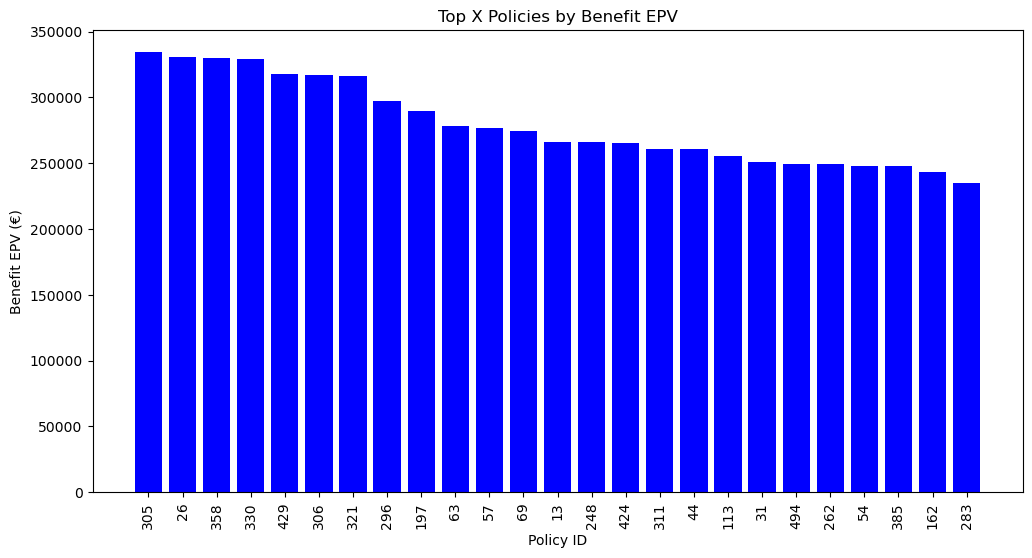

In [176]:

sorted_policies=Portfolio_Attributes.sort_values("benefit_epv",ascending=False)

x=0
total_epv=0
concentration=0

while concentration<20:
    total_epv+=sorted_policies["benefit_epv"].iloc[x]
    x+=1
    concentration=total_epv/Portfolio_Attributes["benefit_epv"].sum()*100

print("Top X:",x)
print("Concentration (%):",concentration)



Portfolio_Attributes["epv_share_pct"]=Portfolio_Attributes["benefit_epv"]/Portfolio_Attributes["benefit_epv"].sum()*100

sorted_policies=Portfolio_Attributes.sort_values("benefit_epv",ascending=False)

x=0
total_epv=0
concentration=0

while concentration<20:
    total_epv+=sorted_policies["benefit_epv"].iloc[x]
    x+=1
    concentration=total_epv/Portfolio_Attributes["benefit_epv"].sum()*100

top_x_policies=sorted_policies.head(x)

top_x_summary=top_x_policies[["policy_id","age","product_type","sum_insured","benefit_epv","epv_share_pct"]]

print(top_x_summary)

top_x_epv=top_x_policies["benefit_epv"].sum()
top_x_concentration=top_x_epv/Portfolio_Attributes["benefit_epv"].sum()*100

print("Top X:",x)
print("Top X Total Benefit EPV:",top_x_epv)
print("Top X Concentration (%):",top_x_concentration)
print("Top X Policy Count Share (%):",x/len(Portfolio_Attributes)*100)

plt.figure(figsize=(12,6))
plt.bar(top_x_policies["policy_id"].astype(str),top_x_policies["benefit_epv"],color="blue")
plt.xlabel("Policy ID")
plt.ylabel("Benefit EPV (€)")
plt.title("Top X Policies by Benefit EPV")
plt.xticks(rotation=90)
plt.show()

count       500.000000
mean      68291.593614
std       74789.417406
min         213.313782
25%        7818.260151
50%       44911.561636
75%      101542.441557
max      334517.235609
Name: benefit_epv, dtype: float64


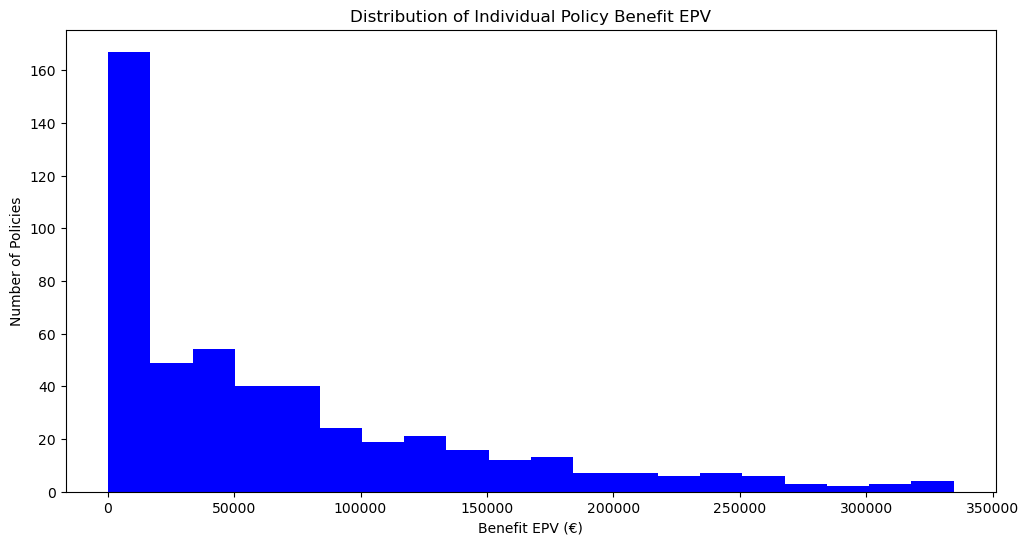

       group  policy_count  total_benefit_epv  average_benefit_epv  \
0      Top X            25       6.991436e+06        279657.437524   
1  Remaining           475       2.715436e+07         57167.075514   

   epv_share_pct  
0      20.475246  
1      79.524754  


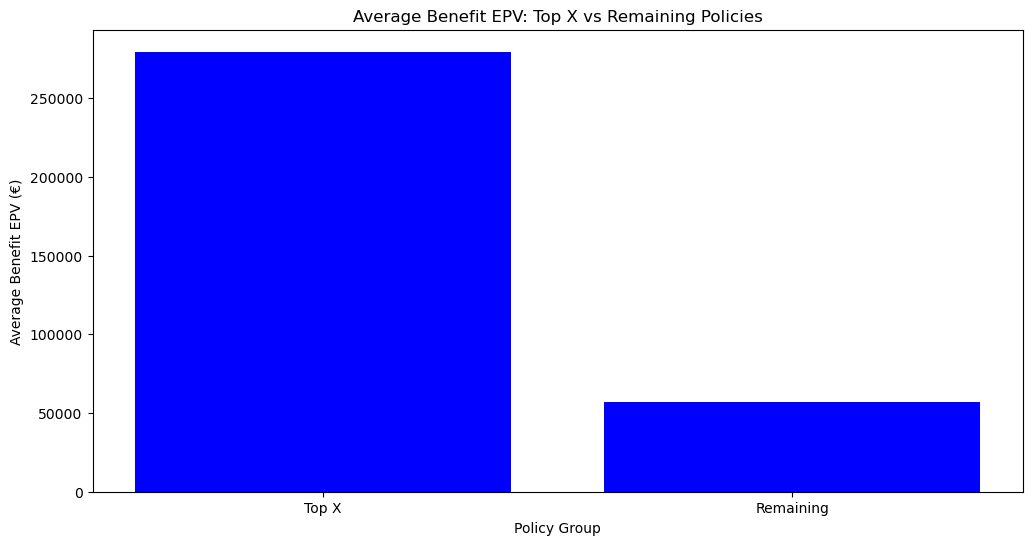

In [178]:
epv_distribution=Portfolio_Attributes["benefit_epv"].describe()
print(epv_distribution)

plt.figure(figsize=(12,6))
plt.hist(Portfolio_Attributes["benefit_epv"],bins=20,color="blue")
plt.xlabel("Benefit EPV (€)")
plt.ylabel("Number of Policies")
plt.title("Distribution of Individual Policy Benefit EPV")
plt.show()

remaining_policies=sorted_policies.iloc[x:]

top_x_average_epv=top_x_policies["benefit_epv"].mean()
remaining_average_epv=remaining_policies["benefit_epv"].mean()

epv_comparison=pd.DataFrame({
    "group":["Top X","Remaining"],
    "policy_count":[len(top_x_policies),len(remaining_policies)],
    "total_benefit_epv":[top_x_policies["benefit_epv"].sum(),remaining_policies["benefit_epv"].sum()],
    "average_benefit_epv":[top_x_average_epv,remaining_average_epv]
})

epv_comparison["epv_share_pct"]=epv_comparison["total_benefit_epv"]/epv_comparison["total_benefit_epv"].sum()*100

print(epv_comparison)

plt.figure(figsize=(12,6))
plt.bar(epv_comparison["group"],epv_comparison["average_benefit_epv"],color="blue")
plt.xlabel("Policy Group")
plt.ylabel("Average Benefit EPV (€)")
plt.title("Average Benefit EPV: Top X vs Remaining Policies")
plt.show()

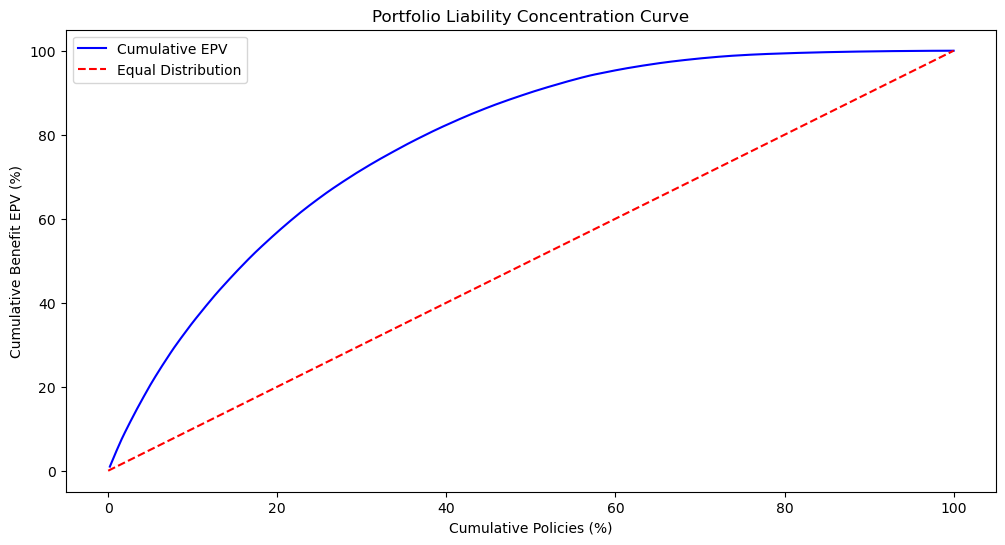

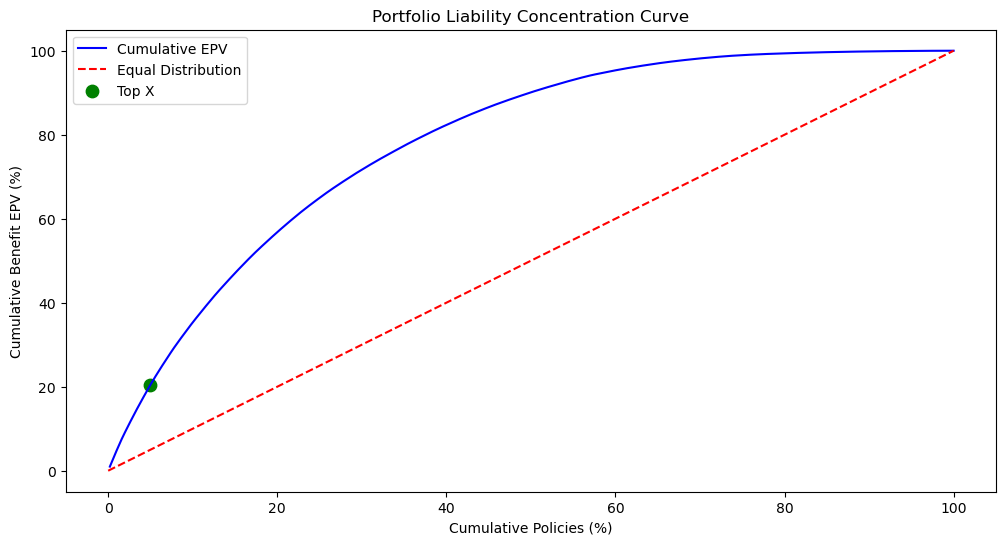

In [180]:

sorted_policies=Portfolio_Attributes.sort_values("benefit_epv",ascending=False).copy()

sorted_policies["cumulative_epv"]=sorted_policies["benefit_epv"].cumsum()

sorted_policies["cumulative_epv_pct"]=sorted_policies["cumulative_epv"]/sorted_policies["benefit_epv"].sum()*100

sorted_policies["cumulative_policy_pct"]=np.arange(1,len(sorted_policies)+1)/len(sorted_policies)*100

plt.figure(figsize=(12,6))
plt.plot(sorted_policies["cumulative_policy_pct"],sorted_policies["cumulative_epv_pct"],color="blue",label="Cumulative EPV")
plt.plot([0,100],[0,100],color="red",linestyle="--",label="Equal Distribution")
plt.xlabel("Cumulative Policies (%)")
plt.ylabel("Cumulative Benefit EPV (%)")
plt.title("Portfolio Liability Concentration Curve")
plt.legend()
plt.show()
plt.figure(figsize=(12,6))

plt.plot(sorted_policies["cumulative_policy_pct"],sorted_policies["cumulative_epv_pct"],color="blue",label="Cumulative EPV")
plt.plot([0,100],[0,100],color="red",linestyle="--",label="Equal Distribution")

plt.scatter(x/len(sorted_policies)*100,top_x_concentration,color="green",s=80,label="Top X")

plt.xlabel("Cumulative Policies (%)")
plt.ylabel("Cumulative Benefit EPV (%)")
plt.title("Portfolio Liability Concentration Curve")
plt.legend()
plt.show()

In [183]:
portfolio_summary=pd.DataFrame({"Metric":["Total Policies",
              "Total Sum Insured",
              "Total Benefit EPV",
              "Average Sum Insured",
              "Average Benefit EPV",
              "Total Gross Annual Premium"],
            "Value":[len(Portfolio_Attributes),
             Portfolio_Attributes["sum_insured"].sum(),
             Portfolio_Attributes["benefit_epv"].sum(),
             Portfolio_Attributes["sum_insured"].mean(),
             Portfolio_Attributes["benefit_epv"].mean(),
             Portfolio_Attributes["gross_annual_premium"].sum()]})

print(portfolio_summary)


business_summary=Portfolio_Attributes.groupby("product_type").agg(
    policy_count=("policy_id","count"),
    total_sum_insured=("sum_insured","sum"),
    total_benefit_epv=("benefit_epv","sum"),
    average_benefit_epv=("benefit_epv","mean"),
    total_gross_annual_premium=("gross_annual_premium","sum")
)

business_summary["policy_share_pct"]=business_summary["policy_count"]/len(Portfolio_Attributes)*100

business_summary["epv_share_pct"]=business_summary["total_benefit_epv"]/Portfolio_Attributes["benefit_epv"].sum()*100

print(business_summary)

                       Metric         Value
0              Total Policies  5.000000e+02
1           Total Sum Insured  1.405300e+08
2           Total Benefit EPV  3.414580e+07
3         Average Sum Insured  2.810600e+05
4         Average Benefit EPV  6.829159e+04
5  Total Gross Annual Premium  2.793240e+06
              policy_count  total_sum_insured  total_benefit_epv  \
product_type                                                       
Endowment              158           45100000       2.326933e+07   
Term                   166           45670000       1.178370e+06   
Whole Life             176           49760000       9.698098e+06   

              average_benefit_epv  total_gross_annual_premium  \
product_type                                                    
Endowment           147274.231061                2.180766e+06   
Term                  7098.616075                1.018440e+05   
Whole Life           55102.829721                5.106302e+05   

              policy_shar

In [194]:
Portfolio_review="""In this portfolio cosisted of 500 policies, total sum insured and total benefit epv are 140530000 and 34145800.
The reason for explaining why total benefit epv is much lower than total sum insured is the influence by mortality,survival probability and discount rates"""

Portfolio_Composition="""Whole life insurance products policies are the most among all types of products in this portfolio.
We can notice that the relative difference of the numbers of different insurance products are relatively small,
which means the portfolio is relatively balanced in terms of policy count"""

Liability_Contribution="""we can observe that endowment insurance products contribute obviously most to the total benefit epv,
However,those policies account for a disproportion large share because its high epvs are likely to be mainly contributed by maturity payment rather than policy count alone.
The share of Whole life insurance policies compares with its share of benefit epv relatively close to 1, 
which means that its contribution to the total benefit epv is approximately proportional to its share of the total number of policies.
However the share of term insurance products is much higher compared with its share of benefit epv,
which means this products contributes marginally to the total benefit epv on average.
The situation for the endowment products are opposite from term products.Which means each endowment insurance polices contributes a lot to the total benefit epv."""

Liability_Intensity="""
It is noticable that the endowment insurance products own the highest average benefit epv.
Maturity payments,different mortality and different discount years all influence average benefit epv,causing significant difference across distinct products.
However,a higher average benefit epv does not necessarily indicate higher insurance risk because benefit epv measures expected liabilities rather than the uncertainty of actual benefit payments.
So a higher average benefit epv does not always appear with a higher premium, and a higher premium does not necessarily lower the insurance risk."""

Business_Recommendations="""
For insurance company, they should pay more attention on the endowment insurance products because of ALM concerns
The main potential ALM concern is the high concentration of Benefit EPV in Endowment Insurance products.
Although Endowment policies account for only 31.6% of the total policies, they contribute approximately 68.15% of the Total Benefit EPV.
Since Endowment Insurance includes maturity payments, a large number of policies maturing around the same time could create significant cash outflows, which could place substantial pressure on the insurer's liquidity.
Therefore, the insurer should carefully monitor the timing of maturity payments and ensure that sufficient liquid assets are available to meet future obligations.
Additionally, mismatches between the timing of asset cash flows and liability payments could create Asset-Liability Management risks.

We can say that the mortality assumption, interest rates and product structures all can affect portfolio's expected liabilities.
First of all , higher mortality can lead to higher benefit epvs of term and whole life insurance.Because the death benefit payment can be more likely to occur in the insured term,
or the death benefit can happen earlier.For endowment benefit the maturity benefit epv can be lower because its maturity payments are less likely to occur or the number of payments can be smaller.However,the total endowment benefit epv may increase or decrease depending on the changes in death benefit epv and maturity benefit epv.

Secondly, interest rates affect expected liabilities through discounting. 
Higher interest rates generally reduce the present value of future benefit payments, w
hile lower interest rates increase it. Long-term liabilities are usually more sensitive to changes in interest rates.

Finally, different product structures lead to different expected liabilities. 
Term Insurance only provides death benefits during a certain period, 
while Whole Life Insurance provides lifetime death coverage. 
Endowment Insurance includes both death benefits and maturity benefits, 
which helps explain its relatively high Benefit EPV in this portfolio."""


Portfolio Review
In this portfolio cosisted of 500 policies, total sum insured and total benefit epv are 140530000 and 34145800.
The reason for explaining why total benefit epv is much lower than total sum insured is the influence by mortality,survival probability and discount rates

Portfolio Composition
Whole life insurance products policies are the most among all types of products in this portfolio.
We can notice that the relative difference of the numbers of different insurance products are relatively small,
which means the portfolio is relatively balanced in terms of policy count

Liability Contribution
we can observe that endowment insurance products contribute obviously most to the total benefit epv,
However,those policies account for a disproportion large share because its high epvs are likely to be mainly contributed by maturity payment rather than policy count alone.
The share of Whole life insurance policies compares with its share of benefit epv relatively close to 1, 
whic

In [200]:
Synthetic_Portfolio="""Real insurance company data is difficult to access because I do not have permission to use it.

Synthetic data may differ significantly from real insurance data because it may not fully reflect real-world policyholder characteristics and risk patterns. Therefore, the results obtained from a synthetic portfolio may be less representative of an actual insurance portfolio."""

Mortality_Assumptions="""The Makeham mortality model calculates mortality rates using fixed parameters. However, actual mortality rates may change due to technological progress and improvements in medical care, which could reduce mortality rates. On the other hand, accidents and unexpected events could lead to higher mortality rates than predicted by the model.

If the actual mortality rates are higher than predicted by the model, the Benefit EPV of Term Life Insurance will generally increase because the probability of death benefit payments occurring during the insurance term becomes higher."""

Interest_Rate_Assumptions="""In reality, interest rates may change over time. The Benefit EPV will also change as interest rates change. Higher interest rates generally lead to lower Benefit EPVs, while lower interest rates generally lead to higher Benefit EPVs."""

Policyholder_Behaviour="""In reality, policyholders may lapse or surrender their insurance policies, which could change the number of active policies in the portfolio. As a result, the total Benefit EPV and future premium income may change. However, the model does not consider these policyholder behaviours."""

Terminal_Age_Limitation="""In reality, some policyholders may live beyond the age of 100. However, the model stops calculating cash flows after age 100. Therefore, potential benefit payments occurring after age 100 are not considered, which may lead to an underestimation of expected liabilities."""


print("Stage 10.4 — Model Assumptions & Limitations")
print()

print("10.4.1 Synthetic Portfolio")
print(Synthetic_Portfolio)
print()

print("10.4.2 Mortality Assumptions")
print(Mortality_Assumptions)
print()

print("10.4.3 Interest Rate Assumptions")
print(Interest_Rate_Assumptions)
print()

print("10.4.4 Policyholder Behaviour")
print(Policyholder_Behaviour)
print()

print("10.4.5 Terminal Age Limitation")
print(Terminal_Age_Limitation)

Stage 10.4 — Model Assumptions & Limitations

10.4.1 Synthetic Portfolio
Real insurance company data is difficult to access because I do not have permission to use it.

Synthetic data may differ significantly from real insurance data because it may not fully reflect real-world policyholder characteristics and risk patterns. Therefore, the results obtained from a synthetic portfolio may be less representative of an actual insurance portfolio.

10.4.2 Mortality Assumptions
The Makeham mortality model calculates mortality rates using fixed parameters. However, actual mortality rates may change due to technological progress and improvements in medical care, which could reduce mortality rates. On the other hand, accidents and unexpected events could lead to higher mortality rates than predicted by the model.

If the actual mortality rates are higher than predicted by the model, the Benefit EPV of Term Life Insurance will generally increase because the probability of death benefit payments o

In [207]:


Project_Overview="""I used Python and the Makeham mortality model to price
Term Life, Whole Life, and Endowment Insurance products.
Then, I conducted analyses of portfolio cash flows,
the sensitivity of Benefit EPV to interest rates and mortality assumptions,
liability concentration, and portfolio risk and business implications."""

Key_Findings="""We found that Endowment Insurance accounts for only 31.6%
of the total policies but contributes approximately 68.15% of the Total Benefit EPV.
This indicates a high concentration of expected benefit liabilities
in Endowment Insurance products, which may create potential liquidity
and Asset-Liability Management (ALM) risks."""

Learning_Outcomes="""Through this project, I learned how to apply a mortality model
to life insurance pricing using Python, given assumptions about
the sum insured and interest rates.
I also developed practical skills in building actuarial models,
performing calculations, and analysing insurance portfolios
to investigate relevant actuarial and business problems."""


print("Stage 10.5 — Final Conclusion")
print()

print("Project Overview")
print(Project_Overview)
print()

print("Key Findings")
print(Key_Findings)
print()

print("Learning Outcomes")
print(Learning_Outcomes)


Stage 10.5 — Final Conclusion

Project Overview
I used Python and the Makeham mortality model to price
Term Life, Whole Life, and Endowment Insurance products.
Then, I conducted analyses of portfolio cash flows,
the sensitivity of Benefit EPV to interest rates and mortality assumptions,
liability concentration, and portfolio risk and business implications.

Key Findings
We found that Endowment Insurance accounts for only 31.6%
of the total policies but contributes approximately 68.15% of the Total Benefit EPV.
This indicates a high concentration of expected benefit liabilities
in Endowment Insurance products, which may create potential liquidity
and Asset-Liability Management (ALM) risks.

Learning Outcomes
Through this project, I learned how to apply a mortality model
to life insurance pricing using Python, given assumptions about
the sum insured and interest rates.
I also developed practical skills in building actuarial models,
performing calculations, and analysing insurance portfol

In [222]:
import os
import json

notebook_path="/Users/aixuanli/project.ipynb"

print("File Exists:",os.path.exists(notebook_path))

if os.path.exists(notebook_path):
    with open(notebook_path,encoding="utf-8") as f:
        notebook=json.load(f)

    print("Total Cells:",len(notebook["cells"]))
    print("Total Lines:",sum(
        len("".join(cell["source"]).splitlines())
        for cell in notebook["cells"]
    ))
    print("Stage 10.5 Found:",any(
        "Learning_Outcomes=" in "".join(cell["source"])
        for cell in notebook["cells"]
    ))

File Exists: True
Total Cells: 15
Total Lines: 863
Stage 10.5 Found: True
